In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
from skimage import io

import matplotlib.pyplot as plt
import seaborn as sb


%load_ext autoreload
%autoreload 2

In [3]:
dirnames = {
    'R1':Path('/Users/xies/Library/CloudStorage/OneDrive-Stanford/Skin/Two photon/Shared/K10 paw/K10-R1/Uncropped'),
    'R2':Path('/Users/xies/Library/CloudStorage/OneDrive-Stanford/Skin/Two photon/Shared/K10 paw/K10-R2/Uncropped'),
    # 'R4':Path('/Users/xies/Library/CloudStorage/OneDrive-Stanford/Skin/Two photon/Shared/K10 paw/K10-R4/Uncropped'),
    # 'R5':Path('/Users/xies/Library/CloudStorage/OneDrive-Stanford/Skin/Two photon/Shared/K10 paw/K10-R5/Uncropped'),
    'R3':Path('/Users/xies/Library/CloudStorage/OneDrive-Stanford/Skin/Two photon/Shared/K10 paw/Time course/Prelim analysis/t0')
}

mouse = {'R1':'mouse1','R2':'mouse2','R3':'mouse3'}

# Calculate curvature given mesh

In [ ]:
from trimesh import Trimesh
from measurements import get_tissue_curvature_over_grid, get_mesh_from_bm_image

kappa = 10
name = 'R3'

height_image = io.imread(dirnames[name] / 'height_image.tif')
heightmap = np.argmax(height_image,axis=0)
mesh = get_mesh_from_bm_image(height_image)
# mesh = Trimesh(np.load(dirnames[name] / 'bm_mesh.npz')['vertices'][:,[2,1,0]],
#                np.load(dirnames[name] / 'bm_mesh.npz')['faces'])
meanC, gaussC = get_tissue_curvature_over_grid(mesh,height_image.shape,kappa=10)
io.imsave(dirnames[name] / f'mean_curvature_kappa{kappa}.tif',meanC.T)

# Correlate K10 and curvature

In [162]:
flat_k10

array([[ 1850,  2215,  3275, ...,  4942,  5337,  4938],
       [ 1949,  1825,  2726, ...,  5736,  4854,  5037],
       [ 1866,  1874,  2689, ...,  5470,  5104,  4929],
       ...,
       [ 2224,  2589,  3691, ..., 10968, 10848,  7373],
       [ 2086,  2386,  3761, ..., 11288,  9738,  6509],
       [ 2086,  2614,  3973, ..., 10860, 11820,  7668]], dtype=uint16)

/var/folders/zp/5k1kvm9j0t19cvq8h628kr8h0000gn/T/ipykernel_23836/2658418227.py:37: FutureWarning: `imshow` is deprecated since version 0.25 and will be removed in version 0.27. Please use `matplotlib`, `napari`, etc. to visualize images.
  io.imshow(flat_k10_MIP_th)
/opt/miniconda3/envs/jupyter/lib/python3.12/site-packages/skimage/io/_plugins/matplotlib_plugin.py:158: UserWarning: Low image data range; displaying image with stretched contrast.
  lo, hi, cmap = _get_display_range(image)


(0.5, 1.5)

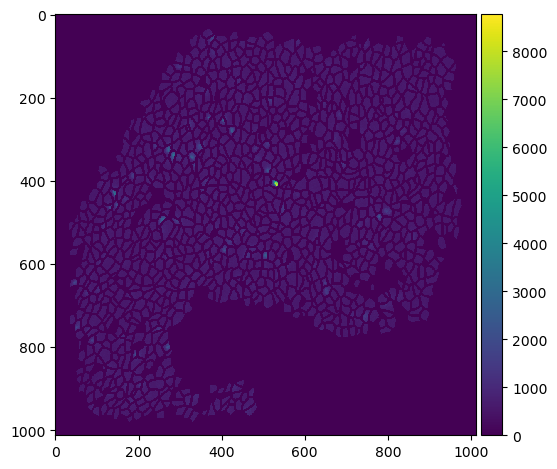

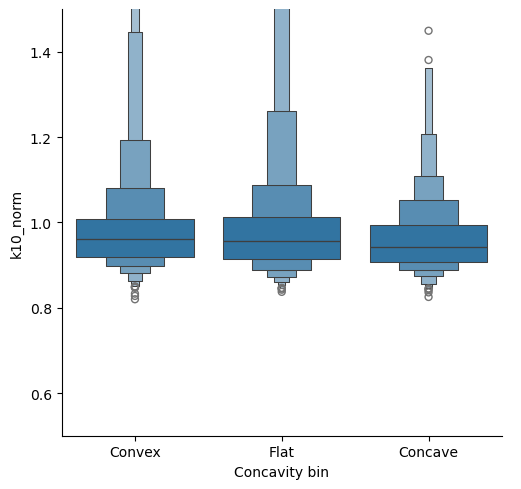

In [110]:
name = 'R2'
from skimage import filters
from imageUtils import shrink_labels

kappa = 10

flat_k10 = io.imread(dirnames[name] / 'k10_resliced.tif')
flat_k10_MIP = flat_k10[15:20,:].max(axis=0)
mask = io.imread( dirnames[name] / 'cp_masks.tif')

mask = shrink_labels(mask,border_pixels=3)

flat_k10_MIP[mask == 0] = 0
th = filters.threshold_otsu(flat_k10_MIP)
flat_k10_MIP_th = flat_k10_MIP.copy()
flat_k10_MIP_th[flat_k10_MIP_th < th] = 0
# curvature = np.load(dirnames[name] / 'mean_curvature.npz')['mean_curvature']
curvature = io.imread(dirnames[name] / f'mean_curvature_kappa{kappa}.tif')

from skimage import measure
_df = pd.DataFrame(measure.regionprops_table(mask,intensity_image = curvature,
                                            properties = ['label','area','mean_intensity']))
_df = _df.rename(columns={'mean_intensity':'curvature'})
_df = pd.merge(_df,pd.DataFrame(measure.regionprops_table(mask,intensity_image = flat_k10_MIP_th,
                                            properties = ['mean_intensity'])),
               left_index=True,right_index=True)
_df = _df.rename(columns={'mean_intensity':'k10'})
_df['k10_norm'] = _df['k10'] / _df['k10'].mean()
# _df['log_k10_norm'] = np.log(_df['k10'] / _df['k10'].mean())
_df['Concavity'] = _df['curvature'] > 0
_df['Name'] = name
_df.loc[(_df['curvature'] > -0.1) & (_df['curvature'] < 0.1),'Concavity bin'] = 'Flat'
_df.loc[(_df['curvature'] > 0.1),'Concavity bin'] = 'Concave'
_df.loc[(_df['curvature'] < -0.1),'Concavity bin'] = 'Convex'
_df.to_csv(dirnames[name] / 'k10_v_curvature.csv')

io.imshow(flat_k10_MIP_th)
sb.catplot(_df,x='Concavity bin',y='k10_norm',kind='boxen',order= ['Convex','Flat','Concave'])
plt.ylim([.5,1.5])

# Batch plotting

In [85]:
# df[df['Name'] == 'R2']['Log-K10'].mean()

In [86]:
df[df['Name'] == 'R2']['k10'].mean()

np.float64(656.8643609872341)

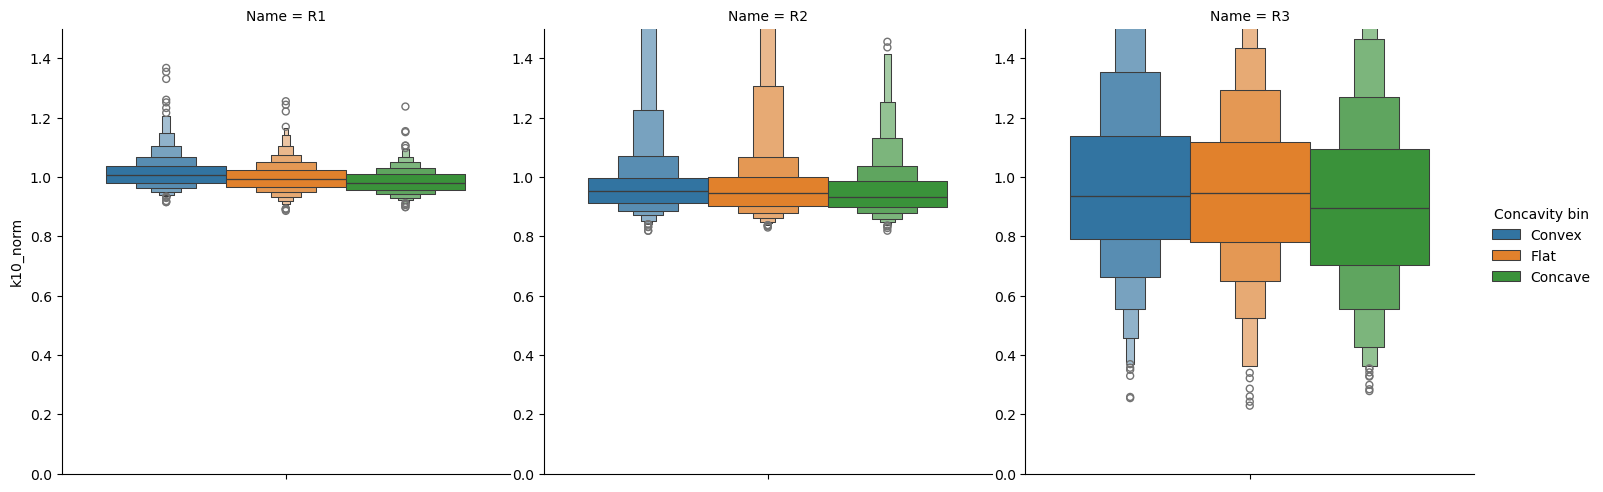

<Figure size 640x480 with 0 Axes>

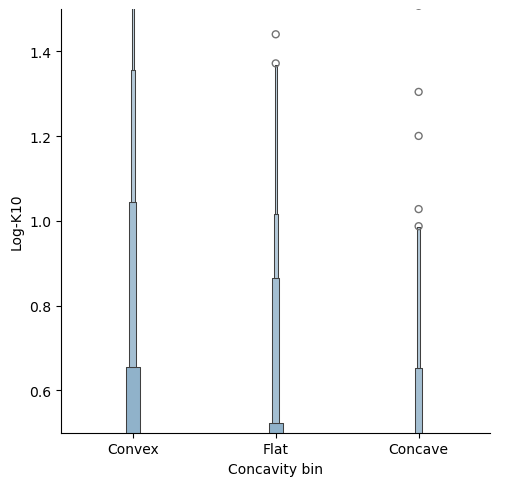

In [102]:
df = pd.concat([pd.read_csv(dirnames['R1'] /'k10_v_curvature.csv',index_col=0),
               pd.read_csv(dirnames['R2'] /'k10_v_curvature.csv',index_col=0),
               pd.read_csv(dirnames['R3'] /'k10_v_curvature.csv',index_col=0)]
         ,ignore_index=True)

df['Log-K10'] = np.log2(df['k10_norm'])

g = sb.catplot(df,hue='Concavity bin',col='Name',y='k10_norm',kind='boxen',
          hue_order=['Convex','Flat','Concave'],sharey=False)
# plt.ylim([0.5,1.5])
g.axes[0,0].set_ylim([0,1.5])
g.axes[0,1].set_ylim([0,1.5])
g.axes[0,2].set_ylim([0,1.5])

plt.savefig('/Users/xies/Library/CloudStorage/OneDrive-Stanford/Skin/Two photon/Shared/K10 paw/Figures/concavity_bin_v_k10.svg')

plt.figure()
g = sb.catplot(df,x='Concavity bin',y='Log-K10',kind='boxen',
          order=['Convex','Flat','Concave'],sharey=False)
# plt.ylim([0.5,1.5])

plt.savefig('/Users/xies/Library/CloudStorage/OneDrive-Stanford/Skin/Two photon/Shared/K10 paw/Figures/concavity_bin_v_k10_merged.svg')


In [101]:
df.groupby(['Name','Concavity bin'])['Log-K10'].mean().reset_index()
# df.groupby(['Name','Concavity bin'])['Log-K10'].std().reset_index()

,Name,Concavity bin,Log-K10
0,R1,Concave,-0.022939
1,R1,Convex,0.018619
2,R1,Flat,-0.004233
3,R2,Concave,-0.060833
4,R2,Convex,-0.022997
5,R2,Flat,-0.012808
6,R3,Concave,-0.193812
7,R3,Convex,-0.065143
8,R3,Flat,-0.129654


In [104]:
# _df

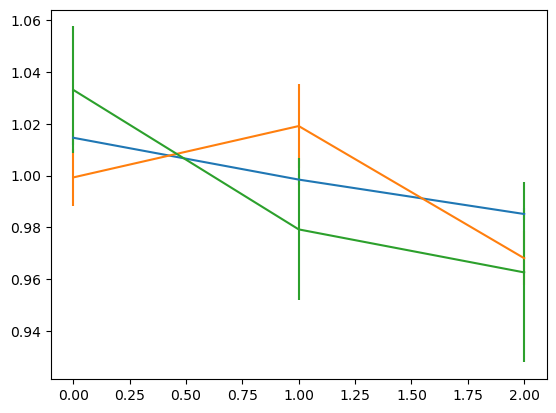

In [111]:
plt.figure()
_df = pd.DataFrame()
_df['Mean'] = df.groupby(['Name','Concavity bin'])['k10_norm'].mean()
_df['Std'] = df.groupby(['Name','Concavity bin'])['k10_norm'].std()
_df['Count'] = df.groupby(['Name','Concavity bin'])['k10_norm'].count()

for n in ['R1','R2','R3']:

    plt.errorbar([0,1,2],
                 _df.loc[n,:].loc[['Convex','Flat','Concave']]['Mean'],
                 _df.loc[n,:].loc[['Convex','Flat','Concave']]['Std'] / np.sqrt(_df.loc[n,:].loc[['Convex','Flat','Concave']]['Count']))
    plt.savefig('/Users/xies/Library/CloudStorage/OneDrive-Stanford/Skin/Two photon/Shared/K10 paw/Figures/concavity_bin_v_k10_lineplot.svg')

In [112]:
from scipy import stats

print(stats.ttest_ind(
_df.reorder_levels(axis=0,order=[1,0]).loc['Concave']['Mean'],
_df.reorder_levels(axis=0,order=[1,0]).loc['Convex']['Mean']))

print(stats.ttest_ind(
_df.reorder_levels(axis=0,order=[1,0]).loc['Flat']['Mean'],
_df.reorder_levels(axis=0,order=[1,0]).loc['Convex']['Mean']))

print(stats.ttest_ind(
_df.reorder_levels(axis=0,order=[1,0]).loc['Concave']['Mean'],
_df.reorder_levels(axis=0,order=[1,0]).loc['Flat']['Mean']))

TtestResult(statistic=np.float64(-3.673204828649506), pvalue=np.float64(0.02133094292305828), df=np.float64(4.0))
TtestResult(statistic=np.float64(-1.107357500782391), pvalue=np.float64(0.33024468644568183), df=np.float64(4.0))
TtestResult(statistic=np.float64(-2.017018729080001), pvalue=np.float64(0.11388396858575733), df=np.float64(4.0))


<Axes: xlabel='Concavity bin', ylabel='k10_norm'>

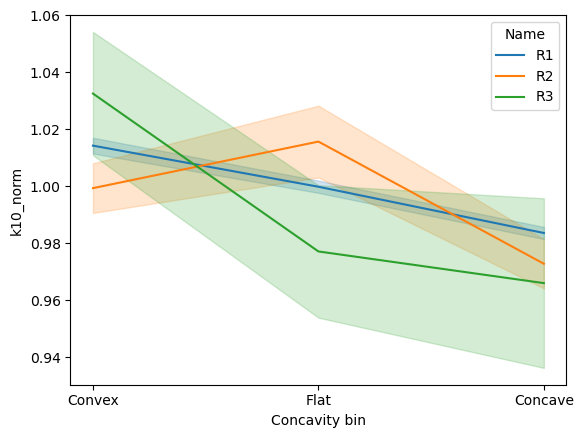

In [21]:
plt.figure()
sb.lineplot(df,x='Concavity bin',y='k10_norm',hue='Name',errorbar='se')

In [18]:
df['Concavity bin'] = pd.Categorical(df['Concavity bin'],categories=['Convex','Flat','Concave'])

In [67]:
from scipy.stats import ttest_ind

for mouse,_df in df.groupby('Name'):
    conv = _df.set_index('Concavity bin').loc['Convex']
    flat = _df.set_index('Concavity bin').loc['Flat']
    conc = _df.set_index('Concavity bin').loc['Concave']

    print(f'Mouse = {mouse}')
    print('Convex v. flat')
    print(ttest_ind(conv['k10_norm'],flat['k10_norm']).pvalue)
    print('Flat v. concave')
    print(ttest_ind(conc['k10_norm'],flat['k10_norm']).pvalue)
    print('Convex v. concave')
    print(ttest_ind(conv['k10_norm'],conc['k10_norm']).pvalue)

_df = df.copy()
conv = _df.set_index('Concavity bin').loc['Convex']
flat = _df.set_index('Concavity bin').loc['Flat']
conc = _df.set_index('Concavity bin').loc['Concave']

print(f'Mouse = ALL')
print('Convex v. flat')
print(ttest_ind(conv['Log-K10'],flat['Log-K10']).pvalue)
print('Flat v. concave')
print(ttest_ind(conc['Log-K10'],flat['Log-K10']).pvalue)
print('Convex v. concave')
print(ttest_ind(conv['Log-K10'],conc['Log-K10']).pvalue)

Mouse = R1
Convex v. flat
3.3090823552712256e-05
Flat v. concave
5.271782046933124e-07
Convex v. concave
4.809108575465125e-17
Mouse = R2
Convex v. flat
0.31787143707402493
Flat v. concave
0.017641200441947825
Convex v. concave
0.03497439099786499
Mouse = R3
Convex v. flat
0.11180094493391428
Flat v. concave
0.7772219281795909
Convex v. concave
0.06582504522376242
Mouse = ALL
Convex v. flat
0.6391319172934026
Flat v. concave
3.401959607620704e-05
Convex v. concave
5.894278788939544e-05


-0.28761650508875874
-0.20762568697418293
-0.062001138085696954


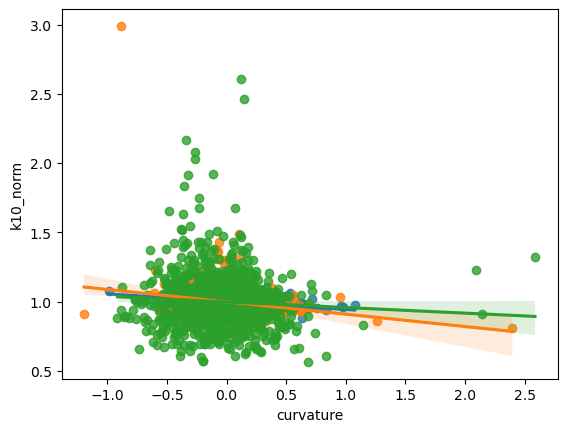

In [186]:
from basicUtils import nonan_pairs
for mouse,_df in df.groupby('Name'):
    sb.regplot(_df,x='curvature',y='k10_norm')
    X,Y = nonan_pairs(_df['curvature'],_df['k10_norm'])
    R = np.corrcoef(X,Y)
    
    print(R[0,1])
    

In [21]:
G = io.imread('/Users/xies/Library/CloudStorage/OneDrive-Stanford/Skin/Two photon/Shared/K10 paw/K10-R2/Uncropped/G.tif')
R = io.imread('/Users/xies/Library/CloudStorage/OneDrive-Stanford/Skin/Two photon/Shared/K10 paw/K10-R2/Uncropped/R.tif')
B = io.imread('/Users/xies/Library/CloudStorage/OneDrive-Stanford/Skin/Two photon/Shared/K10 paw/K10-R2/Uncropped/B.tif')
heightmap = io.imread('/Users/xies/Library/CloudStorage/OneDrive-Stanford/Skin/Two photon/Shared/K10 paw/K10-R2/Uncropped/heightmap.tif')

from imageUtils import reslice_by_heightmap

flat_B = reslice_by_heightmap(B,heightmap,bottom_border=20,top_border=-30)
flat_G = reslice_by_heightmap(G,heightmap,bottom_border=20,top_border=-30)
flat_R = reslice_by_heightmap(R,heightmap,bottom_border=20,top_border=-30)

In [22]:
io.imsave('/Users/xies/Library/CloudStorage/OneDrive-Stanford/Skin/Two photon/Shared/K10 paw/K10-R2/Uncropped/flat_B.tif',flat_B)
io.imsave('/Users/xies/Library/CloudStorage/OneDrive-Stanford/Skin/Two photon/Shared/K10 paw/K10-R2/Uncropped/flat_G_larger.tif',flat_G)
io.imsave('/Users/xies/Library/CloudStorage/OneDrive-Stanford/Skin/Two photon/Shared/K10 paw/K10-R2/Uncropped/flat_R_larger.tif',flat_R)


/opt/miniconda3/envs/jupyter/lib/python3.12/site-packages/skimage/_shared/utils.py:328: UserWarning: /Users/xies/Library/CloudStorage/OneDrive-Stanford/Skin/Two photon/Shared/K10 paw/K10-R2/Uncropped/flat_B.tif is a low contrast image
  return func(*args, **kwargs)
/opt/miniconda3/envs/jupyter/lib/python3.12/site-packages/skimage/_shared/utils.py:328: UserWarning: /Users/xies/Library/CloudStorage/OneDrive-Stanford/Skin/Two photon/Shared/K10 paw/K10-R2/Uncropped/flat_R_larger.tif is a low contrast image
  return func(*args, **kwargs)


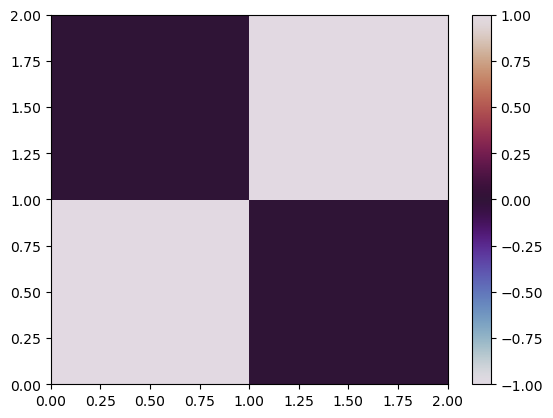

In [33]:
plt.pcolor(np.eye(2),cmap='twilight',vmax=1,vmin=-1);plt.colorbar()
plt.savefig('/Users/xies/Library/CloudStorage/OneDrive-Stanford/Skin/Two photon/Shared/K10 paw/K10-R2/Uncropped/colorbar_twilight.svg')
